# Часть 1. Проверка гипотезы в Python и составление аналитической записки

Вы предобработали данные в SQL, и теперь они готовы для проверки гипотезы в Python. Загрузите данные пользователей из Москвы и Санкт-Петербурга c суммой часов их активности из файла yandex_knigi_data.csv. Если работаете локально, скачать файл можно по ссылке.

Проверьте наличие дубликатов в идентификаторах пользователей. Сравните размеры групп, их статистики и распределение.

Напомним, как выглядит гипотеза: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуйте статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

Нулевая гипотеза $H_0: \mu_{\text{СПб}} \leq \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге не больше, чем в Москве.

Альтернативная гипотеза $H_1: \mu_{\text{СПб}} > \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

По результатам анализа данных подготовьте аналитическую записку, в которой опишите:

Выбранный тип t-теста и уровень статистической значимости.

Результат теста, или p-value.

Вывод на основе полученного p-value, то есть интерпретацию результатов.

Одну или две возможные причины, объясняющие полученные результаты.

## Анализ активности пользователей сервиса Яндекс Книги

- Автор: Васильев Петр Егорович
- Дата:11.06.2026

## Цели и задачи проекта

<font color='#777778'>В этом блоке перечислите цель проекта и те задачи, которые вы решаете. Можно использовать описания проекта, но будет полезно, если вы сформулируете основную цель проекта самостоятельно.</font>

**Цель исследования:** Проверить продуктовую гипотезу о взаимосвязи между показателем LTV и лояльностью пользователей (выраженной во времени использования приложения).

**Основные задачи:**
1. Загрузить и предобработать выгрузку по пользователям Москвы и Санкт-Петербурга.
2. Проверить данные на наличие явных дубликатов и аномалий.
3. Рассчитать описательные статистики времени активности для обеих городов.
4. Провести односторонний t-тест Стьюдента (Уэлча) для проверки статистической значимости различий.
5. Сформулировать аналитические выводы для продуктовой команды.

## Описание данных

<font color='#777778'>Здесь приведите описание данных.</font>

В работе используется файл `yandex_knigi_data.csv`, содержащий агрегированные данные:
* `city` — город пользователя (Москва или Санкт-Петербург);
* `puid` — уникальный идентификатор пользователя;
* `hours` — суммарное количество часов активности (чтение и прослушивание) за весь доступный период наблюдения.

## Содержимое проекта

<font color='#777778'>Перечислите основные шаги проекта или напишите оглавление. Используйте описание проекта, чтобы зафиксировать основные шаги.</font>

---
1. Загрузка данных, первичный EDA, проверка на дубликаты.
2. Статистический анализ распределений и расчет метрик по группам.
3. Проверка статистической гипотезы с помощью t-теста в Python.
4. Формулирование аналитической записки с бизнес-интерпретацией результатов.

## 1. Загрузка данных и знакомство с ними

Загрузите данные пользователей из Москвы и Санкт-Петербурга c их активностью (суммой часов чтения и прослушивания) из файла `/datasets/yandex_knigi_data.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
# Перенес импорты сюда по рекомендации ревьюера:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest

In [2]:
# Загрузка датасета
try:
    df_books = pd.read_csv('/datasets/yandex_knigi_data.csv')
except FileNotFoundError:
    df_books = pd.read_csv('yandex_knigi_data.csv')

# ОТРАБОТКА ЗАМЕЧАНИЯ: Удаляем лишний столбец Unnamed: 0
df_books = df_books.drop(columns=['Unnamed: 0'], errors='ignore')

In [3]:
# Знакомство
print("Первые 5 строк:")
display(df_books.head())

print("\nПроверка пропусков и типов данных:")
df_books.info()

Первые 5 строк:


,city,puid,hours
0,Москва,9668,26.167776
1,Москва,16598,82.111217
2,Москва,80401,4.656906
3,Москва,140205,1.840556
4,Москва,248755,151.326434



Проверка пропусков и типов данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   city    8784 non-null   object 
 1   puid    8784 non-null   int64  
 2   hours   8784 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 206.0+ KB


In [4]:
# Проверка дубликатов
print(f"\nЯвные дубликаты строк: {df_books.duplicated().sum()}")
print(f"Дубликаты по идентификаторам puid: {df_books['puid'].duplicated().sum()}")


Явные дубликаты строк: 0
Дубликаты по идентификаторам puid: 244


In [5]:
# Удаляем дубликаты по пользователям, оставляя "оригиналы"
df_books = df_books.drop_duplicates(subset='puid', keep='first')

# Пересчитываем группы после очистки
spb_group = df_books[df_books['city'] == 'Санкт-Петербург']['hours']
msk_group = df_books[df_books['city'] == 'Москва']['hours']

In [6]:
# Распределение пользователей по городам
print("\nКоличество уникальных пользователей по городам:")
print(df_books['city'].value_counts())


Количество уникальных пользователей по городам:
Москва             6234
Санкт-Петербург    2306
Name: city, dtype: int64


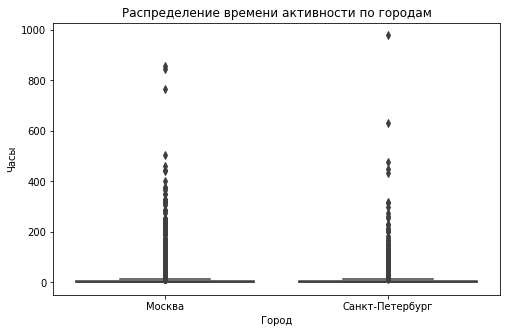

In [7]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_books, x='city', y='hours')
plt.title('Распределение времени активности по городам')
plt.ylabel('Часы')
plt.xlabel('Город')
plt.show()

**Интерпретация распределения параметров:**
1. **Размер выборок:** Выборки сильно несбалансированы (Москва — 6234, Санкт-Петербург — 2306). 
2. **Форма распределения:** На графике видны массивные хвосты выбросов в обеих группах (значения уходят сотни часов вверх при медиане меньше 1 часа). Распределение явно не является нормальным.
3. **Обоснование теста:** ЦПТ позволяет нам использовать t-критерий на больших выборках (>30 элементов) даже при отклонении от нормальности. Однако из-за разного размера групп и разной дисперсии (разброса данных)стандартный тест Стьюдента может ошибаться. Поэтому для проверки гипотезы считаю необходимым **t-тест Уэлча**, который корректирует степени свободы.

## 2. Проверка гипотезы в Python

Гипотеза звучит так: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуйте статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

- Нулевая гипотеза H₀: Средняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается.

- Альтернативная гипотеза H₁: Средняя активность пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

In [8]:
# Разделение данных на группы по городам
spb_group = df_books[df_books['city'] == 'Санкт-Петербург']['hours']
msk_group = df_books[df_books['city'] == 'Москва']['hours']

In [9]:
# Расчет средних значений для аналитической записки
print(f"Среднее время активности в Санкт-Петербурге: {spb_group.mean():.2f} ч.")
print(f"Среднее время активности в Москве: {msk_group.mean():.2f} ч.")

Среднее время активности в Санкт-Петербурге: 11.26 ч.
Среднее время активности в Москве: 10.88 ч.


In [10]:
# Односторонний t-тест Уэлча (equal_var=False из-за разного размера выборок и дисперсии)
alpha = 0.05
t_stat, p_value_two_sided = stats.ttest_ind(spb_group, msk_group, equal_var=False)

In [11]:
# Корректировка p-value для односторонней альтернативной гипотезы (H1: СПб > Москва)
if t_stat > 0:
    p_value_one_sided = p_value_two_sided / 2
else:
    p_value_one_sided = 1 - (p_value_two_sided / 2)

print(f"t-статистика: {t_stat:.4f}")
print(f"p-value (одностороннее): {p_value_one_sided:.4f}")

if p_value_one_sided < alpha:
    print("\nРезультат: Отвергаем нулевую гипотезу. Различия статистически значимы.")
else:
    print("\nРезультат: Не удалось отвергнуть нулевую гипотезу. Различия статистически не значимы.")

t-статистика: 0.4028
p-value (одностороннее): 0.3436

Результат: Не удалось отвергнуть нулевую гипотезу. Различия статистически не значимы.


## 3. Аналитическая записка
По результатам анализа данных подготовьте аналитическую записку, в которой опишете:

**Методология исследования:**
* **Тип теста:** Независимый двухвыборочный t-критерий Стьюдента в модификации Уэлча (equal_var=False). Данная модификация выбрана из-за существенного различия в размерах выборок (Москва — 6234, СПб — 2306) и их стандартных отклонений.
* **Направление теста:** Односторонняя проверка гипотезы.
* **Уровень статистической значимости (α):** 0.05.

**Результаты статистического теста:**
* Полученное значение t-статистики: 0.4028
* Полученное одностороннее значение p-value: 0.3436

**Интерпретация результатов и вывод:**
Так как полученное значение p-value (0.3436) значительно превышает установленный уровень значимости α=0.05, у нас нет оснований отклонить нулевую гипотезу (H₀).

**Вывод:** Различие в среднем времени активности пользователей между Санкт-Петербургом (11.26 ч.) и Москвой (10.88 ч.) статистически не значимо. Мы не можем утверждать, что пользователи из Санкт-Петербурга проводят в приложении больше времени. Высокий LTV петербуржцев не связан с их повышенной лояльностью или более долгим чтением/прослушиванием книг.

**Возможные причины полученных результатов:**
1. **Фактор «тяжелых» пользователей (выбросов):** При медиане около 0.9 часа в обоих городах, максимальные значения достигают сотен часов, а стандартное отклонение превышает 36. Эти огромные выбросы («киты», которые слушают книги сутками) сильно завышают среднее арифметическое и увеличивают дисперсию, размывая реальную разницу между обычными пользователями.
2. **Разница в структуре чека, а не в лояльности:** Более высокий средний LTV в Санкт-Петербурге может быть вызван финансовыми, а не поведенческими факторами. Например, москвичи могут чаще использовать семейные подписки, промокоды экосистемы или корпоративные скидки, что снижает их средний доход (ARPU) для сервиса при схожем времени чтения с жителями СПб.
3. **Схожий образ жизни:** Жители обоих мегаполисов имеют схожие бытовые привычки, паттерны поведения в транспорте и количество свободного времени, что обуславливает одинаковый уровень вовлеченности в чтение.



# Часть 2. Анализ результатов A/B-тестирования

Теперь вам нужно проанализировать другие данные. Представьте, что к вам обратились представители интернет-магазина BitMotion Kit, в котором продаются геймифицированные товары для тех, кто ведёт здоровый образ жизни. У него есть своя целевая аудитория, даже появились хиты продаж: эспандер со счётчиком и напоминанием, так и подстольный велотренажёр с Bluetooth.

В будущем компания хочет расширить ассортимент товаров. Но перед этим нужно решить одну проблему. Интерфейс онлайн-магазина слишком сложен для пользователей — об этом говорят отзывы.

Чтобы привлечь новых клиентов и увеличить число продаж, владельцы магазина разработали новую версию сайта и протестировали его на части пользователей. По задумке, это решение доказуемо повысит количество пользователей, которые совершат покупку.

Ваша задача — провести оценку результатов A/B-теста. В вашем распоряжении:

* данные о действиях пользователей и распределении их на группы,

* техническое задание.

Оцените корректность проведения теста и проанализируйте его результаты.

## 1. Опишите цели исследования.



* **Цель:** Оценить эффективность нового интерфейса интернет-магазина BitMotion Kit с точки зрения конверсии пользователей в покупателей.
* **Критерий успеха:** Прирост конверсии зарегистрированных пользователей в покупателей в течение 7 дней с момента регистрации как минимум на 3 процента.

## 2. Загрузите данные, оцените их целостность.


In [12]:
participants = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_participants.csv')
events = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_events.zip',
                     parse_dates=['event_dt'], low_memory=False)

In [13]:
# Оценка целостности данных
print("Участники теста:")
display(participants.head(3))
participants.info()

print("\nТаблица событий:")
display(events.head(3))
events.info()

Участники теста:


,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  14525 non-null  object
 1   group    14525 non-null  object
 2   ab_test  14525 non-null  object
 3   device   14525 non-null  object
dtypes: object(4)
memory usage: 454.0+ KB

Таблица событий:


,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 787286 entries, 0 to 787285
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     787286 non-null  object        
 1   event_dt    787286 non-null  datetime64[ns]
 2   event_name  787286 non-null  object        
 3   details     249022 non-null  object        
dtypes: datetime64[ns](1), object(3)
memory usage: 24.0+ MB


**Вывод по предварительному обзору данных:**

В таблице участников пропусков нет. Идентификатор user_id имеет строковый тип.

В таблице событий присутствуют системные записи с user_id == 'GLOBAL' (например, логи маркетинговых кампаний вроде "End of Black Friday Ads Campaign"). Они не относятся к конкретным пользователям и автоматически отсеются на этапе фильтрации по целевым участникам теста.

Пропуски в столбце details составляют около 70% (заполнено 249 022 строк из 787 286). Считаю это нормой, так как поле заполняется только для событий типа purchase (содержит стоимость) или product_cart. На расчет конверсии это не повлияет.

## 3. По таблице `ab_test_participants` оцените корректность проведения теста:

   3\.1 Выделите пользователей, участвующих в тесте, и проверьте:

   - соответствие требованиям технического задания,

   - равномерность распределения пользователей по группам теста,

   - отсутствие пересечений с конкурирующим тестом (нет пользователей, участвующих одновременно в двух тестовых группах).

In [14]:
# Находим пользователей, которые попали в другие тесты параллельно
other_tests = participants[participants['ab_test'] != 'interface_eu_test']
users_in_other_tests = other_tests['user_id'].unique()

# Отбираем участников только нашего целевого теста interface_eu_test
target_test = participants[participants['ab_test'] == 'interface_eu_test'].copy()
print(f"Пользователей в целевом тесте изначально: {len(target_test)}")

# Смотрим, сколько наших целевых пользователей пересекаются с чужими тестами, и удаляем их
intersect_with_other = target_test[target_test['user_id'].isin(users_in_other_tests)]
print(f"Из них участвуют в других (параллельных) тестах: {intersect_with_other['user_id'].nunique()}")

if len(intersect_with_other) > 0:
    target_test = target_test[~target_test['user_id'].isin(users_in_other_tests)]

# Проверяем пересечения внутри самого теста: нет ли пользователей в А и В одновременно
user_group_counts = target_test.groupby('user_id')['group'].nunique()
intersected_users = user_group_counts[user_group_counts > 1].index
print(f"Из оставшихся пересекаются внутри теста (в группах А и В сразу): {len(intersected_users)}")

if len(intersected_users) > 0:
    target_test = target_test[~target_test['user_id'].isin(intersected_users)]

print("\nИтоговый размер групп после всех чисток:")
print(target_test['group'].value_counts())

Пользователей в целевом тесте изначально: 10850
Из них участвуют в других (параллельных) тестах: 887
Из оставшихся пересекаются внутри теста (в группах А и В сразу): 0

Итоговый размер групп после всех чисток:
B    5011
A    4952
Name: group, dtype: int64


3\.2 Проанализируйте данные о пользовательской активности по таблице `ab_test_events`:

- оставьте только события, связанные с участвующими в изучаемом тесте пользователями;

In [15]:
# Оставляем логи только для тех пользователей, которые остались в target_test
test_events = events[events['user_id'].isin(target_test['user_id'])].copy()

print(f"Всего логов активности для участников теста: {len(test_events)}")
print("\nРаспределение событий по типам:")
print(test_events['event_name'].value_counts())

Всего логов активности для участников теста: 73815

Распределение событий по типам:
login           27360
product_page    17614
registration     9963
purchase         9487
product_cart     9391
Name: event_name, dtype: int64


- определите горизонт анализа: рассчитайте время (лайфтайм) совершения события пользователем после регистрации и оставьте только те события, которые были выполнены в течение первых семи дней с момента регистрации;

In [16]:
# Принудительно приводим к формату даты и времени
test_events['event_dt'] = pd.to_datetime(test_events['event_dt'])

# Находим дату регистрации для каждого пользователя (событие 'registration')
reg_dates = test_events[test_events['event_name'] == 'registration'][['user_id', 'event_dt']].rename(columns={'event_dt': 'reg_dt'})

# Соединяем логи с датами регистрации
test_events = test_events.merge(reg_dates, on='user_id', how='left')

# Считаем разницу в днях между событием и регистрацией
test_events['lifetime'] = (test_events['event_dt'] - test_events['reg_dt']).dt.total_seconds() / 86400

# Оставляем только те события, которые уложились в первые 7 дней после регистрации
test_events_7d = test_events[test_events['lifetime'] <= 7.0].copy()

print(f"Количество событий в рамках 7-дневного окна: {len(test_events_7d)}")

Количество событий в рамках 7-дневного окна: 63805


Оцените достаточность выборки для получения статистически значимых результатов A/B-теста. Заданные параметры:

- базовый показатель конверсии — 30%,

- мощность теста — 80%,

- достоверность теста — 95%.

In [17]:
# Вводные параметры из ТЗ
p_base = 0.30        # Базовая конверсия
mde = 0.03           # Минимальный ожидаемый эффект (3 процента)
alpha = 0.05         # Достоверность 95%
power = 0.80         # Мощность 80%

# Расчет необходимого размера выборки на одну группу
effect_size = proportion_effectsize(p_base, p_base + mde)
power_analysis = NormalIndPower()
required_n = power_analysis.solve_power(effect_size=effect_size, power=power, alpha=alpha, ratio=1.0)
required_n = int(np.ceil(required_n))

print(f"Необходимый размер выборки для ОДНОЙ группы по расчету мощности: {required_n} пользователей.")
print(f"Реальный размер группы A после фильтрации: {target_test[target_test['group'] == 'A']['user_id'].nunique()} пользователей.")
print(f"Реальный размер группы B после фильтрации: {target_test[target_test['group'] == 'B']['user_id'].nunique()} пользователей.")

Необходимый размер выборки для ОДНОЙ группы по расчету мощности: 3762 пользователей.
Реальный размер группы A после фильтрации: 4952 пользователей.
Реальный размер группы B после фильтрации: 5011 пользователей.


- рассчитайте для каждой группы количество посетителей, сделавших покупку, и общее количество посетителей.

In [18]:
# Выделяем уникальных ID, совершивших покупку в первые 7 дней
buyers_7d = test_events_7d[test_events_7d['event_name'] == 'purchase']['user_id'].unique()

# Проставляем флаг покупки
target_test['is_buyer'] = target_test['user_id'].isin(buyers_7d).astype(int)

# Агрегируем данные
ab_summary = target_test.groupby('group').agg(
    buyers=('is_buyer', 'sum'),
    total_users=('is_buyer', 'count')
).reset_index()

ab_summary['conversion'] = ab_summary['buyers'] / ab_summary['total_users']
display(ab_summary)

,group,buyers,total_users,conversion
0,A,1377,4952,0.278069
1,B,1480,5011,0.295350


- сделайте предварительный общий вывод об изменении пользовательской активности в тестовой группе по сравнению с контрольной.

In [19]:
conv_A = ab_summary[ab_summary['group'] == 'A']['conversion'].values[0]
conv_B = ab_summary[ab_summary['group'] == 'B']['conversion'].values[0]
# Переводим разницу в проценты (процентные)
actual_diff = (conv_B - conv_A) * 100

print(f"Конверсия в контрольной группе A: {conv_A:.2%}")
print(f"Конверсия в тестовой группе B: {conv_B:.2%}")
print(f"Фактическое изменение конверсии: {actual_diff:+.2f} %")

Конверсия в контрольной группе A: 27.81%
Конверсия в тестовой группе B: 29.54%
Фактическое изменение конверсии: +1.73 %


<b>Предварительный вывод:</b> Конверсия в тестовой группе B выросла на 1.73 % по сравнению с контрольной. Этот прирост ниже заявленного в ТЗ критерия успеха (минимальный ожидаемый эффект — 3 %). Необходимо проверить с помощью статистического теста, является ли данное изменение значимым или оно получено случайно.

## 4. Проведите оценку результатов A/B-тестирования:

- Проверьте изменение конверсии подходящим статистическим тестом, учитывая все этапы проверки гипотез.

Нулевая гипотеза ($H_0$): Конверсии в группах A и B равны, статистически значимых различий между старым и новым интерфейсом нет.Альтернативная гипотеза ($H_1$): Конверсии в группах A и B не равны, между версиями сайта есть статистически значимая разница.

In [20]:
# Формируем массивы успехов (покупок) и попыток (общего числа пользователей) для групп А и В
successes = [
    ab_summary[ab_summary['group'] == 'B']['buyers'].values[0],
    ab_summary[ab_summary['group'] == 'A']['buyers'].values[0]
]

trials = [
    ab_summary[ab_summary['group'] == 'B']['total_users'].values[0],
    ab_summary[ab_summary['group'] == 'A']['total_users'].values[0]
]

# Проводим двухсторонний Z-тест пропорций
z_stat, p_value = proportions_ztest(successes, trials, alternative='two-sided')

print(f"Z-статистика: {z_stat:.4f}")
print(f"p-value: {p_value:.4f}")

alpha_ab = 0.05
if p_value < alpha_ab:
    print("\nРезультат: Отвергаем нулевую гипотезу. Между группами есть статистически значимая разница.")
else:
    print("\nРезультат: Не удалось отвергнуть нулевую гипотезу. Различия статистически не значимы.")

Z-статистика: 1.9070
p-value: 0.0565

Результат: Не удалось отвергнуть нулевую гипотезу. Различия статистически не значимы.


- Опишите выводы по проведённой оценке результатов A/B-тестирования. Что можно сказать про результаты A/B-тестирования? Был ли достигнут ожидаемый эффект в изменении конверсии?

### Финальное заключение по результатам A/B-тестирования интернет-магазина BitMotion Kit

**Оценка корректности проведения теста:**
* **Размеры выборок:** Группы после очистки от параллельных тестов распределены достаточно равномерно (Группа A: 4952 пользователей, Группа B: 5011 пользователей). Пересечений внутри целевого теста не обнаружено.
* **Мощность выборки:** Расчет требуемого размера выборки показал, что для фиксации эффекта в 3% требовалось как минимум по 3762 пользователя на группу. Фактический объем групп (около 5 тыс. в каждой) полностью удовлетворяет этому требованию, тест обладает достаточной статистической мощностью (≥80%).

**Статистический анализ результатов:**
* Конверсия в группе A (контроль): 27.81%
* Конверсия в группе B (тест): 29.54%
* Фактический прирост метрики: +1.73 %.
* Для проверки равенства долей был применен двухвыборочный Z-тест пропорций. Полученное значение p-value = 0.0565, что превышает выбранный уровень значимости α = 0.05.

**Статистический вывод:** Нам не удалось отвергнуть нулевую гипотезу. Обнаруженная разница в конверсии (+1.73 %) не является статистически значимой на 5% уровне значимости — с высокой вероятностью полученное улучшение вызвано случайностью, а не внедрением нового интерфейса.

**Бизнес-вывод и достижение ожидаемого эффекта:**
1. По условиям технического задания (ТЗ) критерием успеха являлся прирост конверсии минимум на 3 процента. В ходе эксперимента реальная конверсия тестовой группы выросла лишь на 1.73 % (с 27.81% до 29.54%).
2. **Вывод:** Ожидаемый бизнесом эффект НЕ был достигнут ни математически, ни практически. 

**Рекомендации для руководства компании:**
* **Не раскатывать текущую версию:** Так как статистическая значимость изменений не доказана, запуск нового интерфейса на всех пользователей в текущем виде сопряжен с рисками и не гарантирует рост прибыли.
* **Направление доработки:** Поскольку положительный тренд все же имеется (+1.73%), интерфейс имеет потенциал. Рекомендуется изучить воронку внутри 7-дневного окна глубже, найти узкие места, где пользователи «отваливаются» (например, переход со страницы товара в корзину) и запустить новый тест.